# 03 – State-Level Energy Demand Forecasting Pipeline

**Author:** Member 3 (Machine Learning Lead)

**Objective:** Build a production-grade ML pipeline that forecasts **monthly energy requirement (MU)** for each of India's 36 States/UTs and projects demand for **September–December 2026** using only historical data (January–August 2026).

## 1. Imports & Configuration

In [215]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score
)
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
)

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('Libraries loaded. Random seed set to 42.')

Libraries loaded. Random seed set to 42.


## 2. Data Ingestion & Audit

The dataset contains **288 observations** (36 states × 8 months: January–August 2026).

In [216]:
df_raw = pd.read_csv('data/processed/fact_power_state_level.csv', parse_dates=['month_start'])

print(f'Shape           : {df_raw.shape}')
print(f'States/UTs      : {df_raw["entity_name"].nunique()}')
print(f'Time Range      : {df_raw["month_start"].min():%b %Y} to {df_raw["month_start"].max():%b %Y}')
print(f'Months          : {sorted(df_raw["month"].unique())}')
print(f'Target (MU)     : min={df_raw["energy_requirement_mu"].min():.0f}, '  
      f'max={df_raw["energy_requirement_mu"].max():.0f}, '  
      f'mean={df_raw["energy_requirement_mu"].mean():.0f}')
print(f'Null counts     : {df_raw["energy_requirement_mu"].isna().sum()} target nulls')

Shape           : (288, 27)
States/UTs      : 36
Time Range      : Jan 2026 to Aug 2026
Months          : [1, 2, 3, 4, 5, 6, 7, 8]
Target (MU)     : min=6, max=20235, mean=4269
Null counts     : 0 target nulls


## 3. State-Level Demand Archetyping (K-Means Clustering)

### Why Cluster at the State Level?

We aggregate each state's 8-month history into a **structural demand profile** with 4 dimensions:

1. **`log_mean_req`** — Baseline demand volume scale (separates mega-states from small UTs)
2. **`summer_surge_pct`** — Percentage demand increase in summer (Apr–Jul) vs non-summer (Jan–Mar, Aug)
3. **`seasonality_ratio`** — $(\text{Max} - \text{Min}) / \text{Mean}$ demand swing
4. **`mean_load_factor`** — Average grid capacity utilization

This produces **36 data points** (one per state), which K-Means groups into coherent demand archetypes. The cluster label is then merged back as a **feature** for the regression model, giving it information about structural demand regime of each state.

In [217]:
# Build structural demand profile for each of the 36 states
# Use only TRAINING months (1-6) for clustering to avoid leakage
df_train_months = df_raw[df_raw['month'] <= 6].copy()

state_profiles = df_train_months.groupby('entity_name').agg(
    mean_req=('energy_requirement_mu', 'mean'),
    max_req=('energy_requirement_mu', 'max'),
    min_req=('energy_requirement_mu', 'min'),
    mean_lf=('load_factor_pct', 'mean'),
).reset_index()

# Compute summer vs non-summer within training months only
summer_req = df_train_months[df_train_months['month'].isin([4, 5, 6])].groupby('entity_name')['energy_requirement_mu'].mean()
non_summer_req = df_train_months[df_train_months['month'].isin([1, 2, 3])].groupby('entity_name')['energy_requirement_mu'].mean()
surge = ((summer_req - non_summer_req) / non_summer_req * 100).reset_index()
surge.columns = ['entity_name', 'summer_surge_pct']
state_profiles = state_profiles.merge(surge, on='entity_name', how='left')

# Derived features
state_profiles['log_mean_req'] = np.log1p(state_profiles['mean_req'])
state_profiles['seasonality_ratio'] = (
    (state_profiles['max_req'] - state_profiles['min_req']) / state_profiles['mean_req']
)

# Handle any NaN/inf from division
state_profiles = state_profiles.fillna(0)
state_profiles = state_profiles.replace([np.inf, -np.inf], 0)

CLUSTER_VARS = ['log_mean_req', 'seasonality_ratio', 'summer_surge_pct', 'mean_lf']
X_clust = RobustScaler().fit_transform(state_profiles[CLUSTER_VARS])

# Find optimal k via silhouette score
sil_scores = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_clust)
    sil_scores.append(silhouette_score(X_clust, labels))

optimal_k = list(range(2, 9))[int(np.argmax(sil_scores))]
print(f'Optimal k = {optimal_k} (Silhouette = {max(sil_scores):.4f})')

# Final clustering
km_final = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
state_profiles['demand_cluster'] = km_final.fit_predict(X_clust)

Optimal k = 3 (Silhouette = 0.4434)


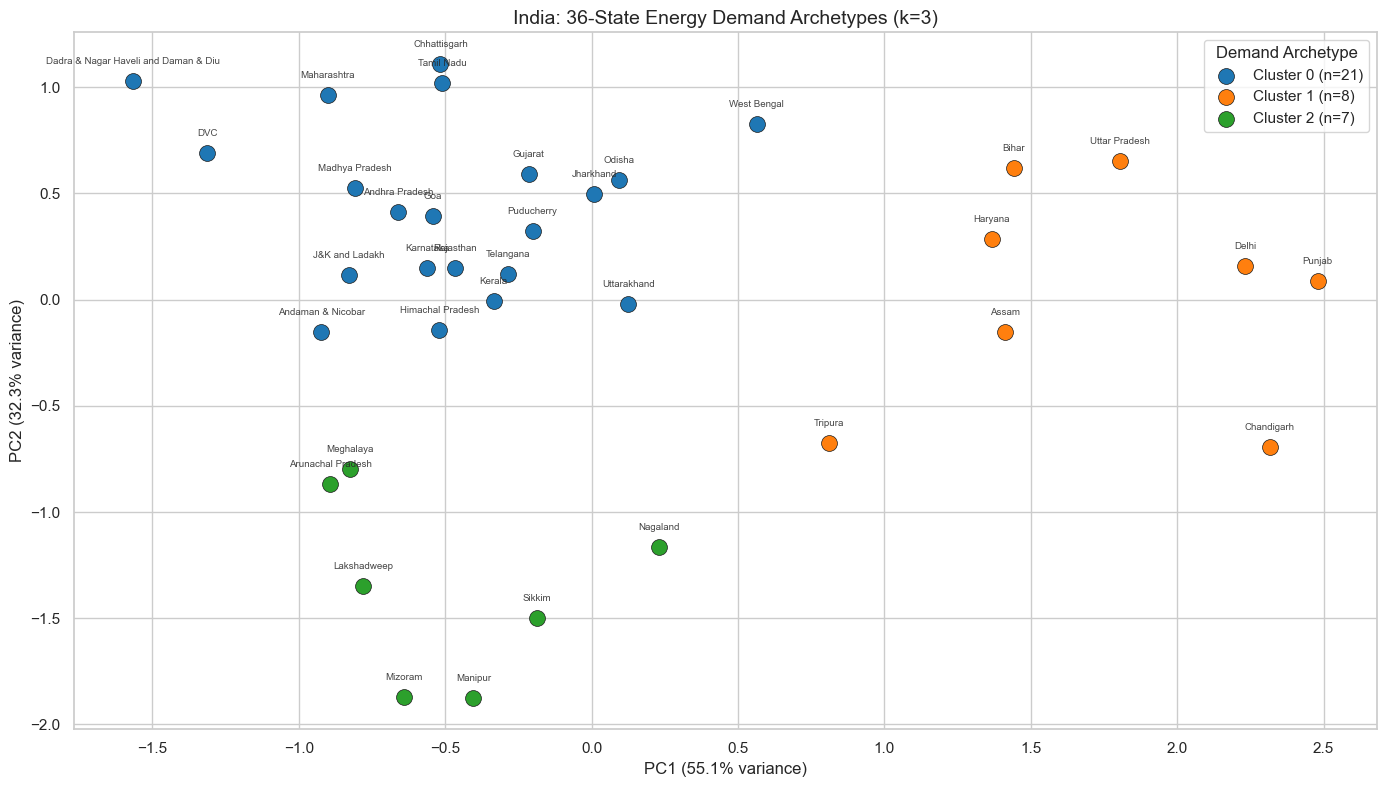

In [218]:
# PCA visualization of the 36-state demand archetypes
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_clust)
state_profiles['PC1'] = coords[:, 0]
state_profiles['PC2'] = coords[:, 1]

plt.figure(figsize=(14, 8))
palette = sns.color_palette('tab10', optimal_k)
for c in range(optimal_k):
    sub = state_profiles[state_profiles['demand_cluster'] == c]
    plt.scatter(sub['PC1'], sub['PC2'], s=130, color=palette[c],
               label=f'Cluster {c} (n={len(sub)})', edgecolors='k', linewidth=0.5)

for _, row in state_profiles.iterrows():
    plt.annotate(row['entity_name'], (row['PC1'], row['PC2'] + 0.08),
                 fontsize=7, ha='center', alpha=0.85)

pct = pca.explained_variance_ratio_ * 100
plt.title(f'India: 36-State Energy Demand Archetypes (k={optimal_k})', fontsize=14)
plt.xlabel(f'PC1 ({pct[0]:.1f}% variance)')
plt.ylabel(f'PC2 ({pct[1]:.1f}% variance)')
plt.legend(title='Demand Archetype')
plt.tight_layout()
plt.show()

In [219]:
# Archetype summary
arch_summary = state_profiles.groupby('demand_cluster').agg(
    Count=('entity_name', 'count'),
    Avg_Demand_MU=('mean_req', lambda s: round(s.mean(), 1)),
    Avg_Summer_Surge=('summer_surge_pct', lambda s: round(s.mean(), 1)),
    Avg_Load_Factor=('mean_lf', lambda s: round(s.mean(), 1)),
    States=('entity_name', lambda s: ', '.join(sorted(s.values)[:5]))
).reset_index()
print('=== State Energy Demand Archetypes ===')
arch_summary

=== State Energy Demand Archetypes ===


,demand_cluster,Count,Avg_Demand_MU,Avg_Summer_Surge,Avg_Load_Factor,States
0,0,21,5446.9,8.5,77.9,"Andaman & Nicobar, Andhra Pradesh, Chhattisgar..."
1,1,8,4287.3,42.0,67.5,"Assam, Bihar, Chandigarh, Delhi, Haryana"
2,2,7,82.9,-1.9,62.2,"Arunachal Pradesh, Lakshadweep, Manipur, Megha..."


## 4. Feature Engineering

### Features used (all knowable BEFORE the target month begins):

| Feature | Description | Why It's Safe |
|---|---|---|
| `log_lag_1_req` | Log of previous month's energy requirement | Available at month start |
| `log_mean_req` | Log of state's historical mean demand | Static state attribute |
| `days_in_month` | Calendar days in the target month | Known in advance |
| `month` | Month number (1–12) | Known in advance |
| `fy_month_index` | Fiscal year month position | Known in advance |
| `is_summer` | Binary: 1 if Apr–Jul, else 0 | Known in advance |
| `rgn_*` | One-hot region dummies | Static state attribute |
| `clust_*` | One-hot demand cluster dummies | Static state attribute |

### Strictly EXCLUDED (concurrent/future information):
- `energy_supplied_mu`, `energy_not_supplied_mu` (only known after month ends)
- `peak_demand_mw`, `peak_met_mw` (only known after month ends)
- Any deficit percentage (arithmetic derivative of target)

In [220]:
# Sort by state → time for correct lag computation
df = df_raw.sort_values(['entity_name', 'month_start']).reset_index(drop=True)

# Merge cluster assignment and historical mean from state profiles
df = df.merge(
    state_profiles[['entity_name', 'demand_cluster', 'log_mean_req']],
    on='entity_name', how='left'
)

# Lag feature: previous month's demand for the SAME state
df['lag_1_req'] = df.groupby('entity_name')['energy_requirement_mu'].shift(1)

# For January (month=1): no prior month exists.
# Fill with the state's mean from training months (1-6), NOT the same row's target.
train_state_means = df[df['month'] <= 6].groupby('entity_name')['energy_requirement_mu'].mean()
jan_mask = df['lag_1_req'].isna()
df.loc[jan_mask, 'lag_1_req'] = df.loc[jan_mask, 'entity_name'].map(train_state_means)

df['log_lag_1_req'] = np.log1p(df['lag_1_req'])

# Seasonal indicator
df['is_summer'] = df['month'].isin([4, 5, 6, 7]).astype(int)

# One-hot encode region and cluster
df = pd.get_dummies(df, columns=['region_code', 'demand_cluster'],
                    prefix=['rgn', 'clust'], drop_first=False, dtype=int)

# Log-transformed target
TARGET = 'log_energy_req'
df[TARGET] = np.log1p(df['energy_requirement_mu'])

FEATURE_COLS = [
    'log_lag_1_req', 'log_mean_req', 'days_in_month',
    'month', 'fy_month_index', 'is_summer',
] + [c for c in df.columns if c.startswith('rgn_') or c.startswith('clust_')]

print(f'Feature count: {len(FEATURE_COLS)}')
print(f'Features: {FEATURE_COLS}')

Feature count: 14
Features: ['log_lag_1_req', 'log_mean_req', 'days_in_month', 'month', 'fy_month_index', 'is_summer', 'rgn_ER', 'rgn_NER', 'rgn_NR', 'rgn_SR', 'rgn_WR', 'clust_0', 'clust_1', 'clust_2']


## 5. Temporal Train / Validation / Test Split

### Why Temporal Split Is Mandatory for Forecasting

In time-series forecasting, the model must **never** see future data during training. A random shuffle violates this fundamentally — it's like reading tomorrow's newspaper to predict today's weather.

| Partition | Months | Rows | Purpose |
|---|---|---|---|
| **Train** | Jan–Jun (1–6) | 216 | Learn demand patterns |
| **Validation** | Jul (7) | 36 | Tune hyperparameters |
| **Test** | Aug (8) | 36 | Final held-out evaluation |
| **Future Forecast** | Sep–Dec (9–12) | 144 | True out-of-sample prediction |

In [221]:
# Temporal split: strictly chronological
df_train = df[df['month'] <= 6].copy()
df_val   = df[df['month'] == 7].copy()
df_test  = df[df['month'] == 8].copy()

print(f'Train      : {len(df_train):>4} rows  |  Months 1-6 (Jan-Jun 2026)  |  {df_train["entity_name"].nunique()} states')
print(f'Validation : {len(df_val):>4} rows  |  Month 7 (Jul 2026)          |  {df_val["entity_name"].nunique()} states')
print(f'Test       : {len(df_test):>4} rows  |  Month 8 (Aug 2026)          |  {df_test["entity_name"].nunique()} states')

Train      :  216 rows  |  Months 1-6 (Jan-Jun 2026)  |  36 states
Validation :   36 rows  |  Month 7 (Jul 2026)          |  36 states
Test       :   36 rows  |  Month 8 (Aug 2026)          |  36 states


## 6. Zero-Leakage Preprocessing

The scaler is fit **only on training data** and applied to validation/test. This prevents any statistical information from future months contaminating the feature scaling.

In [222]:
X_train = df_train[FEATURE_COLS]
y_train = df_train[TARGET]

X_val = df_val[FEATURE_COLS]
y_val = df_val[TARGET]

X_test = df_test[FEATURE_COLS]
y_test = df_test[TARGET]

preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
])

X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc   = preprocessor.transform(X_val)
X_test_proc  = preprocessor.transform(X_test)

print(f'X_train: {X_train_proc.shape}')
print(f'X_val  : {X_val_proc.shape}')
print(f'X_test : {X_test_proc.shape}')

X_train: (216, 14)
X_val  : (36, 14)
X_test : (36, 14)


## 7. Model Benchmarking (Validation Set: July 2026)

We evaluate 6 candidate regressors on the **held-out July data** — a month the models have never seen.

In [223]:
def evaluate(name, model, X_tr, y_tr, X_v, df_v):
    model.fit(X_tr, y_tr)
    pred_log = model.predict(X_v)
    pred_mu  = np.expm1(pred_log)
    actual_mu = df_v['energy_requirement_mu'].values

    # Guard against zero actuals in MAPE
    mask = actual_mu > 0
    mape = np.mean(np.abs((actual_mu[mask] - pred_mu[mask]) / actual_mu[mask])) * 100
    mae  = mean_absolute_error(actual_mu, pred_mu)
    rmse = np.sqrt(mean_squared_error(actual_mu, pred_mu))
    r2   = r2_score(df_v[TARGET], pred_log)

    return {
        'Model': name, 'Val MAPE (%)': round(mape, 2),
        'Val MAE (MU)': round(mae, 1), 'Val RMSE (MU)': round(rmse, 1),
        'Log R²': round(r2, 4), '_model': model,
    }

candidates = [
    ('Ridge',             Ridge(random_state=RANDOM_STATE)),
    ('Lasso',             Lasso(alpha=0.001, random_state=RANDOM_STATE)),
    ('KNN',               KNeighborsRegressor(n_neighbors=5)),
    ('Random Forest',     RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE)),
    ('Extra Trees',       ExtraTreesRegressor(n_estimators=100, random_state=RANDOM_STATE)),
    ('Gradient Boosting', GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE)),
]

results = [evaluate(n, m, X_train_proc, y_train, X_val_proc, df_val) for n, m in candidates]
bench_df = pd.DataFrame([{k:v for k,v in r.items() if k != '_model'} for r in results])
bench_df = bench_df.sort_values('Val MAPE (%)').reset_index(drop=True)

print('=== Validation Leaderboard (July 2026 — True Temporal Hold-Out) ===')
bench_df

=== Validation Leaderboard (July 2026 — True Temporal Hold-Out) ===


,Model,Val MAPE (%),Val MAE (MU),Val RMSE (MU),Log R²
0,Extra Trees,5.99,385.7,805.8,0.9986
1,Gradient Boosting,6.54,401.4,834.4,0.9985
2,Random Forest,7.32,416.7,867.6,0.9982
3,Lasso,8.87,418.2,883.1,0.9976
4,Ridge,10.41,467.2,886.9,0.9967
5,KNN,60.35,1698.5,2810.1,0.9156


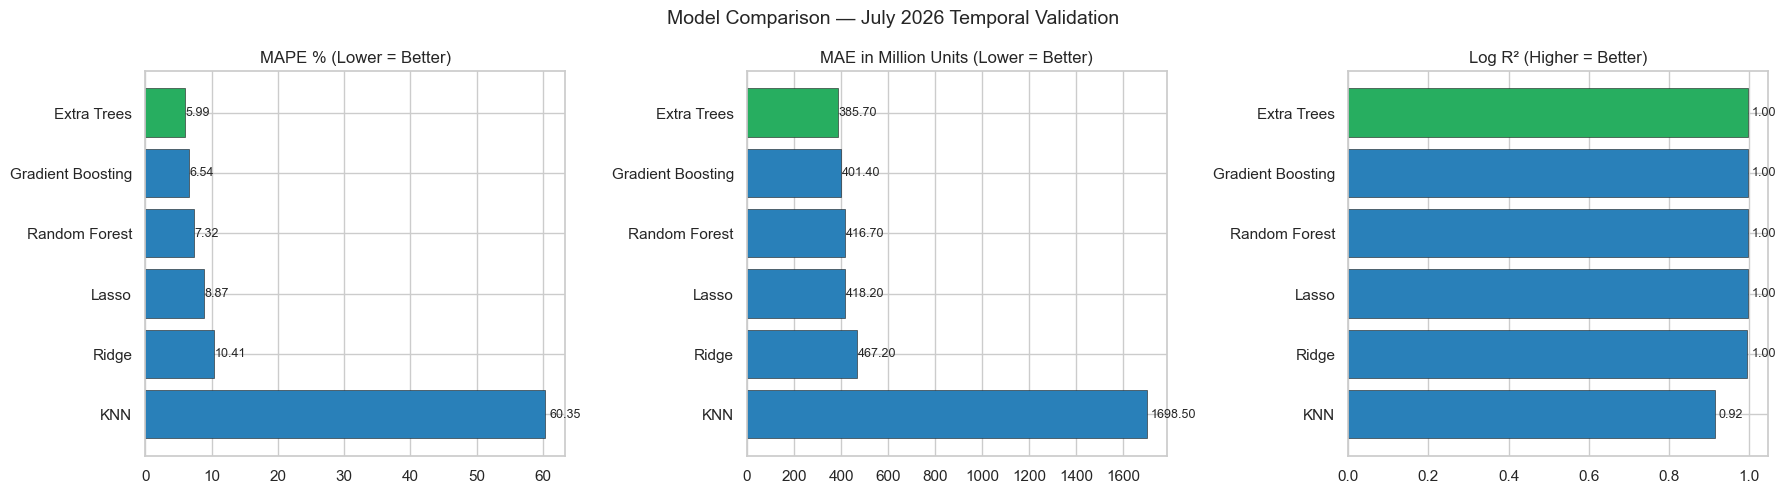

In [224]:
# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (metric, title, asc) in zip(axes, [
    ('Val MAPE (%)', 'MAPE % (Lower = Better)', True),
    ('Val MAE (MU)', 'MAE in Million Units (Lower = Better)', True),
    ('Log R²', 'Log R² (Higher = Better)', False),
]):
    sdf = bench_df.sort_values(metric, ascending=asc)
    best = sdf[metric].iloc[0]
    colors = ['#27ae60' if v == best else '#2980b9' for v in sdf[metric]]
    bars = ax.barh(sdf['Model'], sdf[metric], color=colors, edgecolor='k', linewidth=0.4)
    ax.set_title(title)
    ax.invert_yaxis()
    for bar in bars:
        w = bar.get_width()
        ax.text(w * 1.01, bar.get_y() + bar.get_height()/2, f'{w:.2f}', va='center', fontsize=9)

plt.suptitle('Model Comparison — July 2026 Temporal Validation', fontsize=14)
plt.tight_layout()
plt.show()

## 8. Champion Model: Fine-Tuning & August 2026 Test

We select the best model from validation, tune hyperparameters via 5-fold CV on the training set, then retrain on **Train + Validation (Jan–Jul)** and evaluate on the **sealed August test set**.

In [225]:
# Select champion (lowest validation MAPE)
champion_name = bench_df.iloc[0]['Model']
champion_model = next(r['_model'] for r in results if r['Model'] == champion_name)
print(f'Champion: {champion_name}')

# Hyperparameter grid
param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [None, 8, 12],
    'min_samples_split': [2, 4],
}

gs = GridSearchCV(
    estimator=champion_model.__class__(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=5, n_jobs=1
)
gs.fit(X_train_proc, y_train)
print(f'Best params: {gs.best_params_}')

# Retrain on Train + Val combined (months 1-7)
X_trainval = np.vstack([X_train_proc, X_val_proc])
y_trainval = pd.concat([y_train, y_val], ignore_index=True)

tuned = gs.best_estimator_
tuned.fit(X_trainval, y_trainval)

# Evaluate on sealed August test set
test_pred_log = tuned.predict(X_test_proc)
test_pred_mu  = np.expm1(test_pred_log)
actual_mu     = df_test['energy_requirement_mu'].values

mask = actual_mu > 0
test_mape = np.mean(np.abs((actual_mu[mask] - test_pred_mu[mask]) / actual_mu[mask])) * 100
test_mae  = mean_absolute_error(actual_mu, test_pred_mu)
test_rmse = np.sqrt(mean_squared_error(actual_mu, test_pred_mu))
test_r2   = r2_score(df_test[TARGET], test_pred_log)

print('\n' + '='*60)
print(f'  AUGUST 2026 TEST RESULTS: {champion_name}')
print('='*60)
print(f'  MAPE : {test_mape:.2f}%')
print(f'  MAE  : {test_mae:.1f} MU')
print(f'  RMSE : {test_rmse:.1f} MU')
print(f'  R²   : {test_r2:.4f}')
print('='*60)

Champion: Extra Trees
Best params: {'max_depth': 8, 'min_samples_split': 2, 'n_estimators': 200}

  AUGUST 2026 TEST RESULTS: Extra Trees
  MAPE : 6.65%
  MAE  : 331.8 MU
  RMSE : 577.6 MU
  R²   : 0.9983


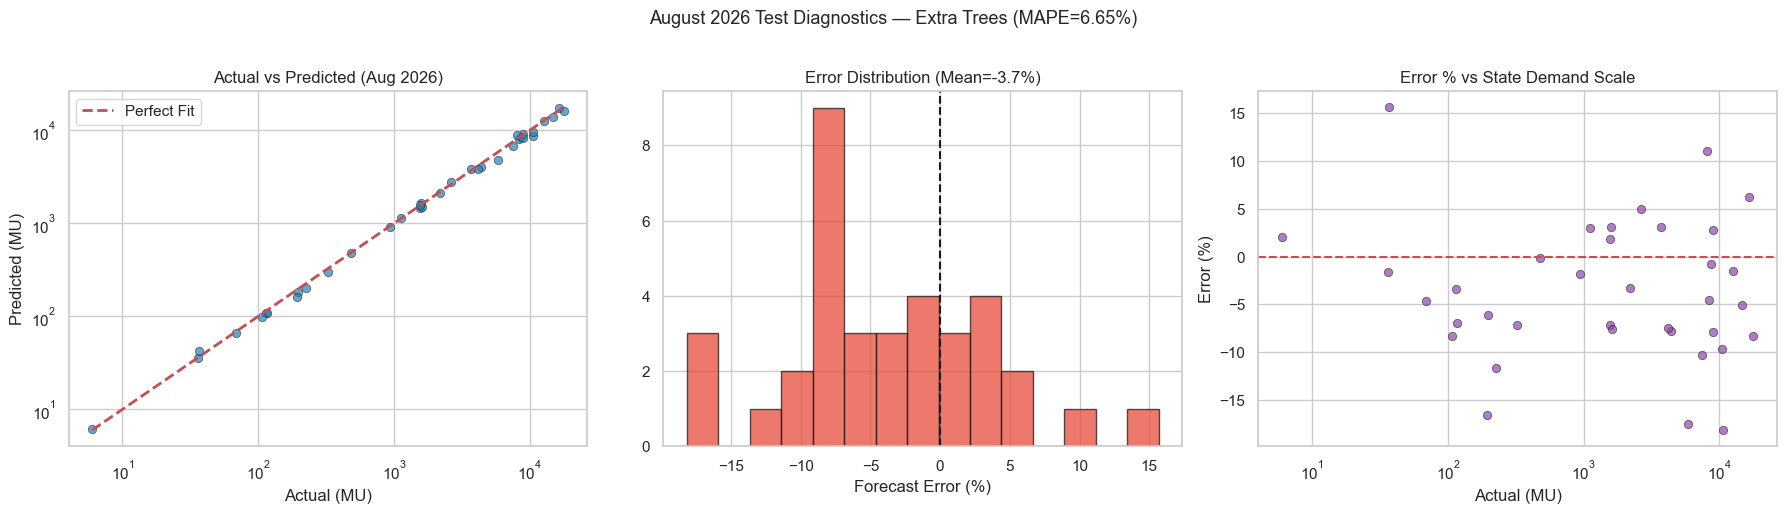

In [226]:
# Diagnostic plots: Actual vs Predicted for August 2026
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Actual vs Predicted (log-log for scale visibility)
axes[0].scatter(actual_mu, test_pred_mu, c='#2980b9', alpha=0.7, edgecolors='k', linewidth=0.5)
lo = min(actual_mu.min(), test_pred_mu.min())
hi = max(actual_mu.max(), test_pred_mu.max())
axes[0].plot([lo, hi], [lo, hi], 'r--', lw=2, label='Perfect Fit')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_title('Actual vs Predicted (Aug 2026)')
axes[0].set_xlabel('Actual (MU)'); axes[0].set_ylabel('Predicted (MU)')
axes[0].legend()

# 2. Error distribution
pct_err = ((test_pred_mu - actual_mu) / actual_mu) * 100
axes[1].hist(pct_err, bins=15, color='#e74c3c', edgecolor='k', alpha=0.75)
axes[1].axvline(0, color='k', lw=1.5, ls='--')
axes[1].set_title(f'Error Distribution (Mean={pct_err.mean():.1f}%)')
axes[1].set_xlabel('Forecast Error (%)')

# 3. Error vs scale
axes[2].scatter(actual_mu, pct_err, c='#8e44ad', alpha=0.7, edgecolors='k', linewidth=0.5)
axes[2].axhline(0, color='r', lw=1.5, ls='--')
axes[2].set_xscale('log')
axes[2].set_title('Error % vs State Demand Scale')
axes[2].set_xlabel('Actual (MU)'); axes[2].set_ylabel('Error (%)')

plt.suptitle(f'August 2026 Test Diagnostics — {champion_name} (MAPE={test_mape:.2f}%)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 9. State-by-State August 2026 Test Report

In [227]:
aug_report = df_test[['entity_name', 'region', 'month_start', 'energy_requirement_mu']].copy()
aug_report['predicted_mu'] = test_pred_mu.round(1)
aug_report['error_mu'] = (aug_report['predicted_mu'] - aug_report['energy_requirement_mu']).round(1)
aug_report['abs_pct_error'] = (
    np.abs(aug_report['error_mu']) / aug_report['energy_requirement_mu'] * 100
).round(2)
aug_report = aug_report.sort_values('energy_requirement_mu', ascending=False).reset_index(drop=True)

print(f'=== August 2026 Forecast Report (36 States) ===')
print(f'States with <5% error  : {(aug_report["abs_pct_error"] < 5).sum()} / 36')
print(f'States with <10% error : {(aug_report["abs_pct_error"] < 10).sum()} / 36')
print(f'Worst error            : {aug_report["abs_pct_error"].max():.1f}% ({aug_report.loc[aug_report["abs_pct_error"].idxmax(), "entity_name"]})')
print()
aug_report.head(15)

=== August 2026 Forecast Report (36 States) ===
States with <5% error  : 15 / 36
States with <10% error : 29 / 36
Worst error            : 18.1% (Punjab)



,entity_name,region,month_start,energy_requirement_mu,predicted_mu,error_mu,abs_pct_error
0,Uttar Pradesh,Northern Region,2026-08-01,17790.0,16313.5,-1476.5,8.30
1,Maharashtra,Western Region,2026-08-01,16448.0,17470.4,1022.4,6.22
2,Gujarat,Western Region,2026-08-01,14767.0,14022.0,-745.0,5.05
3,Tamil Nadu,Southern Region,2026-08-01,12689.0,12499.2,-189.8,1.50
4,Punjab,Northern Region,2026-08-01,10585.0,8663.4,-1921.6,18.15
5,Rajasthan,Northern Region,2026-08-01,10517.0,9495.9,-1021.1,9.71
6,Karnataka,Southern Region,2026-08-01,8941.0,9193.4,252.4,2.82
7,Telangana,Southern Region,2026-08-01,8939.0,8235.5,-703.5,7.87
8,Haryana,Northern Region,2026-08-01,8604.0,8536.7,-67.3,0.78
9,Andhra Pradesh,Southern Region,2026-08-01,8399.0,8018.0,-381.0,4.54


## 10. Recursive Forecast: September–December 2026

### How Recursive (Autoregressive) Forecasting Works

Since September–December 2026 haven't happened yet, we cannot look up actual demand values. Instead, we use a **rolling prediction loop**:

1. **September:** Use August's *actual* demand as `lag_1_req` → Predict September demand
2. **October:** Use September's *predicted* demand as `lag_1_req` → Predict October demand
3. **November:** Use October's *predicted* demand as `lag_1_req` → Predict November demand
4. **December:** Use November's *predicted* demand as `lag_1_req` → Predict December demand

All other features (calendar info, region, cluster, state baseline) are known in advance.

> **Important Caveat:** Recursive forecasting accumulates error — each month's prediction error feeds into the next month's input. The further out we forecast, the wider the uncertainty band. This is an inherent limitation of autoregressive models with limited training data.

In [228]:
# Build the future months feature template
future_months_info = [
    # (month, fy_month_index, days_in_month, is_summer, month_start_str)
    (9,  6, 30, 0, '2026-09-01'),
    (10, 7, 31, 0, '2026-10-01'),
    (11, 8, 30, 0, '2026-11-01'),
    (12, 9, 31, 0, '2026-12-01'),
]

# Get the list of states and their static features
states = df_test[['entity_name']].copy().sort_values('entity_name').reset_index(drop=True)

# Get August actuals as the starting lag for September
aug_actuals = df_test.set_index('entity_name')['energy_requirement_mu'].to_dict()

# Get static features per state (region dummies, cluster dummies, log_mean_req)
static_cols = ['entity_name', 'log_mean_req'] + [c for c in df.columns if c.startswith('rgn_') or c.startswith('clust_')]
# Take one row per state from the existing data
state_static = df.drop_duplicates('entity_name')[static_cols].set_index('entity_name')

# Recursive forecasting loop
all_forecasts = []
prev_month_demand = aug_actuals.copy()  # Start with August actual demand

for month_num, fy_idx, days, is_summer, month_str in future_months_info:
    rows = []
    for state_name in sorted(aug_actuals.keys()):
        lag_val = prev_month_demand[state_name]
        static = state_static.loc[state_name]
        
        row = {
            'log_lag_1_req': np.log1p(lag_val),
            'log_mean_req': static['log_mean_req'],
            'days_in_month': days,
            'month': month_num,
            'fy_month_index': fy_idx,
            'is_summer': is_summer,
        }
        # Add region and cluster dummies
        for col in [c for c in FEATURE_COLS if c.startswith('rgn_') or c.startswith('clust_')]:
            row[col] = static[col]
        rows.append(row)
    
    # Build feature matrix for this future month
    future_df = pd.DataFrame(rows)
    X_future = future_df[FEATURE_COLS]
    X_future_proc = preprocessor.transform(X_future)
    
    # Predict
    pred_log = tuned.predict(X_future_proc)
    pred_mu = np.expm1(pred_log)
    
    # Store results
    for i, state_name in enumerate(sorted(aug_actuals.keys())):
        all_forecasts.append({
            'entity_name': state_name,
            'month_start': month_str,
            'month': month_num,
            'predicted_requirement_mu': round(pred_mu[i], 1),
            'lag_used_mu': round(prev_month_demand[state_name], 1),
        })
        # Update lag for next month's recursive prediction
        prev_month_demand[state_name] = pred_mu[i]

future_forecast_df = pd.DataFrame(all_forecasts)
future_forecast_df['month_start'] = pd.to_datetime(future_forecast_df['month_start'])

print(f'Future forecasts generated: {len(future_forecast_df)} rows (36 states × 4 months)')
print(f'Months forecasted: {sorted(future_forecast_df["month"].unique())}')

Future forecasts generated: 144 rows (36 states × 4 months)
Months forecasted: [9, 10, 11, 12]


In [229]:
# National-level monthly demand forecast summary
national_future = future_forecast_df.groupby('month_start').agg(
    Total_Forecast_MU=('predicted_requirement_mu', 'sum'),
    Avg_State_Forecast=('predicted_requirement_mu', 'mean'),
    Max_State=('predicted_requirement_mu', 'max'),
    Min_State=('predicted_requirement_mu', 'min'),
).reset_index()
national_future['month_start'] = national_future['month_start'].dt.strftime('%b %Y')

# Add August actual for comparison
aug_total = df_test['energy_requirement_mu'].sum()
print(f'August 2026 (Actual)     : {aug_total:,.0f} MU total national demand')
print()
print('=== National Demand Forecast: Sep-Dec 2026 ===')
national_future

August 2026 (Actual)     : 166,553 MU total national demand

=== National Demand Forecast: Sep-Dec 2026 ===


,month_start,Total_Forecast_MU,Avg_State_Forecast,Max_State,Min_State
0,Sep 2026,156830.7,4356.408333,17036.6,6.1
1,Oct 2026,155035.6,4306.544444,17744.6,6.1
2,Nov 2026,150591.9,4183.108333,17495.4,6.1
3,Dec 2026,150124.4,4170.122222,17558.4,6.1


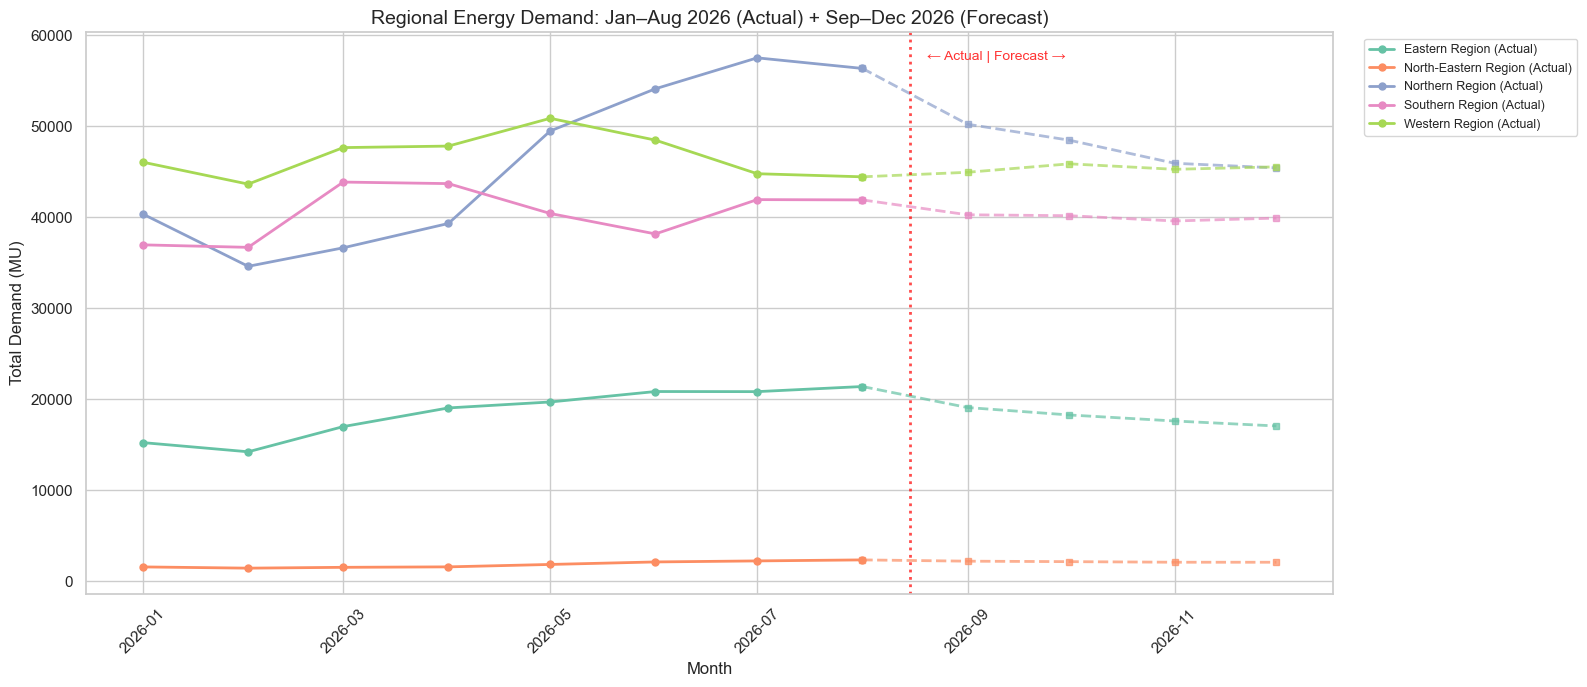

In [230]:
# Visualization: Monthly demand trajectory per region
# Merge region info
region_map = df[['entity_name', 'region']].drop_duplicates().set_index('entity_name')['region']
future_forecast_df['region'] = future_forecast_df['entity_name'].map(region_map)

# Get historical monthly totals by region
hist_regional = df_raw.groupby(['month_start', 'region'])['energy_requirement_mu'].sum().reset_index()
hist_regional.columns = ['month_start', 'region', 'demand_mu']
hist_regional['type'] = 'Actual'

# Future regional totals
fut_regional = future_forecast_df.groupby(['month_start', 'region'])['predicted_requirement_mu'].sum().reset_index()
fut_regional.columns = ['month_start', 'region', 'demand_mu']
fut_regional['type'] = 'Forecast'

combined = pd.concat([hist_regional, fut_regional], ignore_index=True)
combined = combined.sort_values(['region', 'month_start'])

fig, ax = plt.subplots(figsize=(16, 7))
regions = combined['region'].unique()
palette = sns.color_palette('Set2', len(regions))

for i, reg in enumerate(sorted(regions)):
    sub = combined[combined['region'] == reg].sort_values('month_start')
    actual = sub[sub['type'] == 'Actual']
    forecast = sub[sub['type'] == 'Forecast']
    
    ax.plot(actual['month_start'], actual['demand_mu'], '-o', color=palette[i],
            label=f'{reg} (Actual)', linewidth=2, markersize=5)
    
    # Connect last actual to first forecast
    if len(actual) > 0 and len(forecast) > 0:
        bridge = pd.concat([actual.iloc[[-1]], forecast])
        ax.plot(bridge['month_start'], bridge['demand_mu'], '--s', color=palette[i],
                linewidth=2, markersize=5, alpha=0.7)

# Add vertical line at forecast boundary
ax.axvline(pd.Timestamp('2026-08-15'), color='red', linestyle=':', linewidth=2, alpha=0.7)
ax.text(pd.Timestamp('2026-08-20'), ax.get_ylim()[1]*0.95, '← Actual | Forecast →',
        fontsize=10, color='red', alpha=0.8)

ax.set_title('Regional Energy Demand: Jan–Aug 2026 (Actual) + Sep–Dec 2026 (Forecast)', fontsize=14)
ax.set_xlabel('Month')
ax.set_ylabel('Total Demand (MU)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

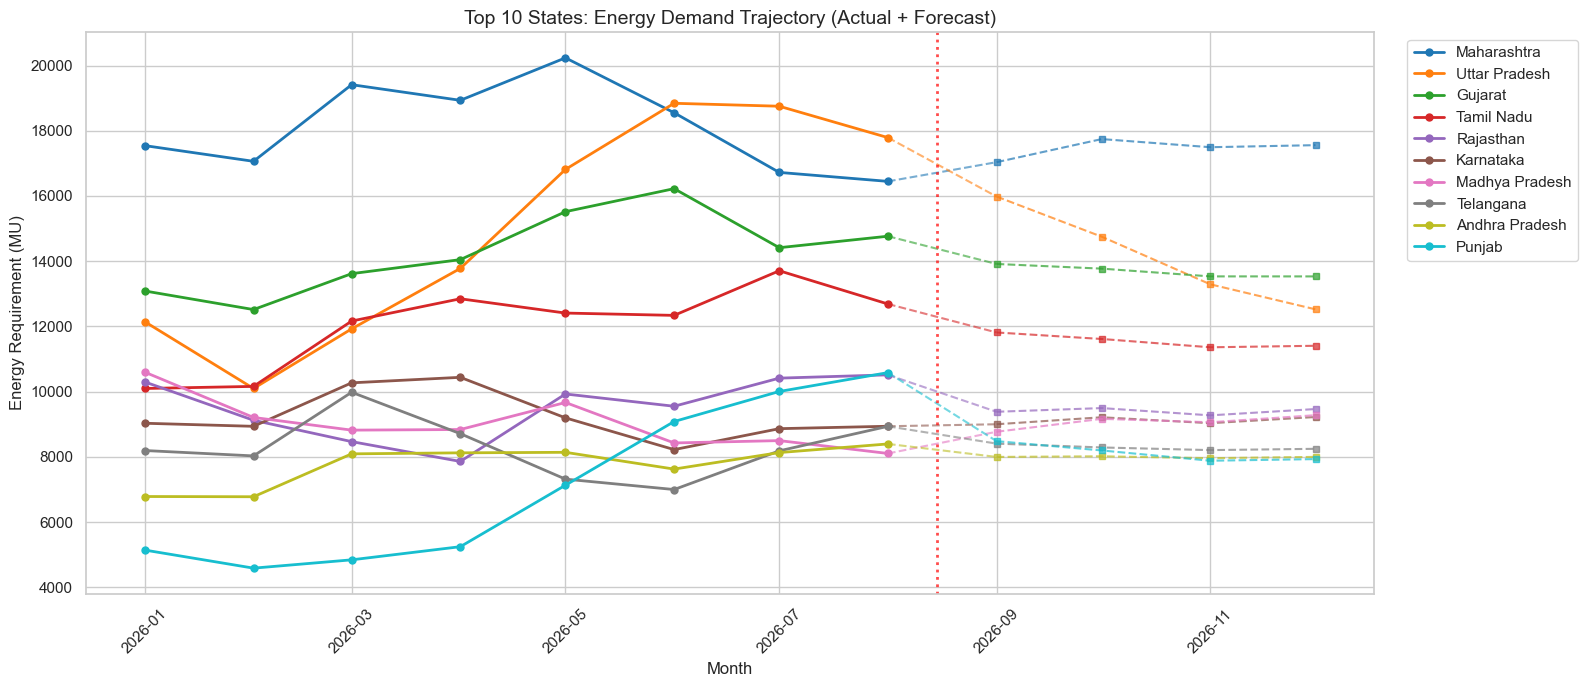

In [231]:
# Top 10 states: Forecasted demand trajectory
top10 = df_raw.groupby('entity_name')['energy_requirement_mu'].mean().nlargest(10).index.tolist()

fig, ax = plt.subplots(figsize=(16, 7))
palette = sns.color_palette('tab10', 10)

for i, state in enumerate(top10):
    # Historical
    hist = df_raw[df_raw['entity_name'] == state].sort_values('month_start')
    ax.plot(hist['month_start'], hist['energy_requirement_mu'], '-o',
            color=palette[i], label=state, linewidth=2, markersize=5)
    
    # Future
    fut = future_forecast_df[future_forecast_df['entity_name'] == state].sort_values('month_start')
    if len(fut) > 0:
        # Bridge from last actual to first forecast
        bridge_x = [hist['month_start'].iloc[-1], fut['month_start'].iloc[0]]
        bridge_y = [hist['energy_requirement_mu'].iloc[-1], fut['predicted_requirement_mu'].iloc[0]]
        ax.plot(bridge_x, bridge_y, '--', color=palette[i], linewidth=1.5, alpha=0.6)
        ax.plot(fut['month_start'], fut['predicted_requirement_mu'], '--s',
                color=palette[i], linewidth=1.5, markersize=5, alpha=0.7)

ax.axvline(pd.Timestamp('2026-08-15'), color='red', ls=':', lw=2, alpha=0.7)
ax.set_title('Top 10 States: Energy Demand Trajectory (Actual + Forecast)', fontsize=14)
ax.set_xlabel('Month')
ax.set_ylabel('Energy Requirement (MU)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 11. Production Exports

We export 3 clean CSV files for **Member 4 (Dashboard Lead)** to import into Power BI / Looker Studio:

1. **`ml_state_demand_forecasts.csv`** — August test predictions + September–December forecasts
2. **`ml_state_demand_archetypes.csv`** — 36-state structural demand profiles
3. **`powerbi_dashboard_master.csv`** — Denormalized master table (all months: actual Jan–Aug + forecast Sep–Dec)

In [232]:
import os
os.makedirs('data/processed', exist_ok=True)

# --- Export 1: Test + Future forecasts ---
# August test predictions
aug_export = aug_report[['entity_name', 'region', 'month_start', 'energy_requirement_mu', 'predicted_mu', 'error_mu', 'abs_pct_error']].copy()
aug_export.columns = ['entity_name', 'region', 'month_start', 'actual_mu', 'predicted_mu', 'error_mu', 'abs_pct_error']
aug_export['forecast_type'] = 'Test (Aug 2026)'

# Future forecasts
fut_export = future_forecast_df[['entity_name', 'region', 'month_start', 'predicted_requirement_mu']].copy()
fut_export.columns = ['entity_name', 'region', 'month_start', 'predicted_mu']
fut_export['actual_mu'] = np.nan
fut_export['error_mu'] = np.nan
fut_export['abs_pct_error'] = np.nan
fut_export['forecast_type'] = 'Future Forecast'
fut_export = fut_export[aug_export.columns]  # Align column order

forecasts_all = pd.concat([aug_export, fut_export], ignore_index=True)
forecasts_all.to_csv('data/processed/ml_state_demand_forecasts.csv', index=False)

# --- Export 2: State archetypes ---
arch_export = state_profiles[['entity_name', 'demand_cluster', 'mean_req',
                              'summer_surge_pct', 'mean_lf', 'seasonality_ratio']].copy()
arch_export.columns = ['entity_name', 'demand_cluster', 'mean_requirement_mu',
                       'summer_surge_pct', 'mean_load_factor_pct', 'seasonality_ratio']
arch_export = arch_export.round(2)

# Human-readable archetype personas based on physical grid characteristics
cluster_stats = state_profiles.groupby('demand_cluster').agg(
    mean_req=('mean_req', 'mean'),
    surge=('summer_surge_pct', 'mean'),
    lf=('mean_lf', 'mean')
)
surge_c = cluster_stats['surge'].idxmax()
low_vol_c = cluster_stats['mean_req'].idxmin()
baseload_c = [c for c in cluster_stats.index if c not in [surge_c, low_vol_c]][0]

archetype_map = {
    surge_c: 'Summer Heatwave Surge Spiker',
    low_vol_c: 'Low-Volume Hill & Island Enclave',
    baseload_c: 'Steady Baseload & High-Utilization Grid'
}
arch_export['archetype_name'] = arch_export['demand_cluster'].map(archetype_map).fillna('Specialized Grid')
arch_export.to_csv('data/processed/ml_state_demand_archetypes.csv', index=False)

# --- Export 3: Power BI master table ---
# Combine historical actuals (Jan-Aug) with future forecasts (Sep-Dec)
historical = df_raw[['entity_name', 'region', 'month_start', 'month',
                     'energy_requirement_mu', 'energy_supplied_mu',
                     'load_factor_pct']].copy()
historical.columns = ['entity_name', 'region', 'month_start', 'month',
                      'actual_mu', 'supplied_mu', 'load_factor_pct']
historical['predicted_mu'] = np.nan
historical['data_type'] = 'Actual'

# Add August test predictions
for _, row in aug_report.iterrows():
    mask = (historical['entity_name'] == row['entity_name']) & (historical['month'] == 8)
    historical.loc[mask, 'predicted_mu'] = row['predicted_mu']

future_master = future_forecast_df[['entity_name', 'region', 'month_start', 'month',
                                    'predicted_requirement_mu']].copy()
future_master.columns = ['entity_name', 'region', 'month_start', 'month', 'predicted_mu']
future_master['actual_mu'] = np.nan
future_master['supplied_mu'] = np.nan
future_master['load_factor_pct'] = np.nan
future_master['data_type'] = 'Forecast'
future_master = future_master[historical.columns]

powerbi = pd.concat([historical, future_master], ignore_index=True)
powerbi = powerbi.merge(arch_export[['entity_name', 'archetype_name', 'demand_cluster']], on='entity_name', how='left')
powerbi = powerbi.sort_values(['entity_name', 'month_start']).reset_index(drop=True)
powerbi.to_csv('data/processed/powerbi_dashboard_master.csv', index=False)

print('Exports complete:')
print(f'  1. ml_state_demand_forecasts.csv  : {len(forecasts_all)} rows')
print(f'  2. ml_state_demand_archetypes.csv  : {len(arch_export)} rows')
print(f'  3. powerbi_dashboard_master.csv    : {len(powerbi)} rows (Jan-Dec 2026)')

Exports complete:
  1. ml_state_demand_forecasts.csv  : 180 rows
  2. ml_state_demand_archetypes.csv  : 36 rows
  3. powerbi_dashboard_master.csv    : 432 rows (Jan-Dec 2026)


## 12. Feature Importance Analysis

Understanding which features drive the champion model's predictions.

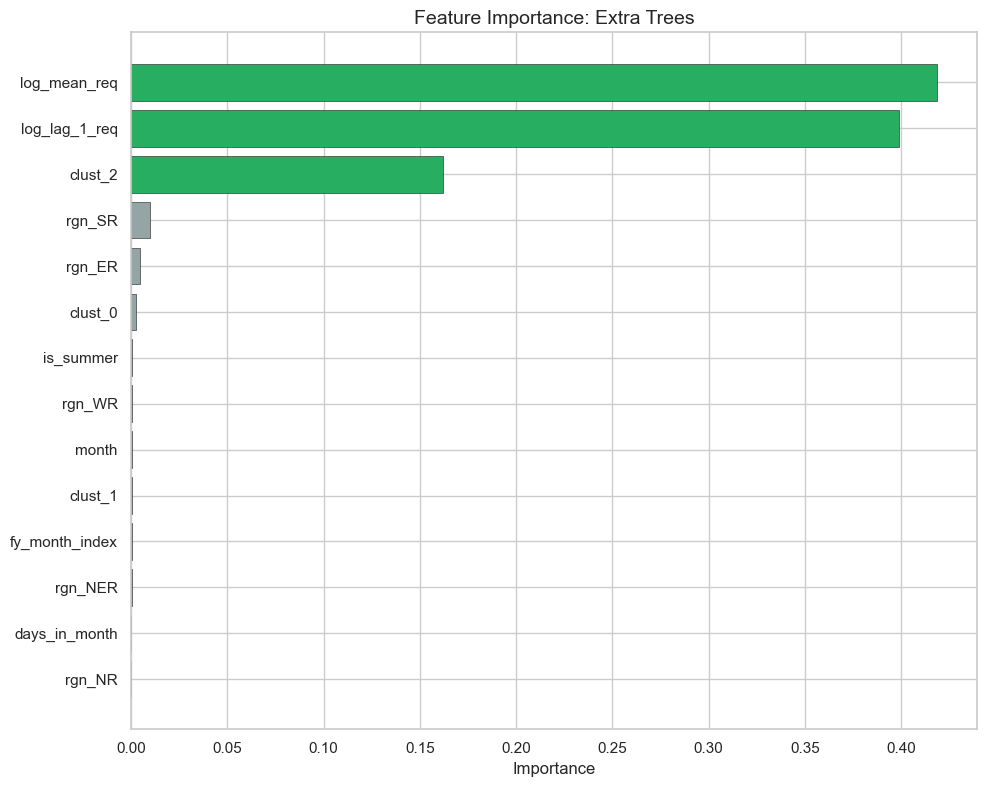


Top 5 Most Important Features:
  log_mean_req              : 0.4184
  log_lag_1_req             : 0.3987
  clust_2                   : 0.1621
  rgn_SR                    : 0.0096
  rgn_ER                    : 0.0048


In [233]:
# Feature importance from the tuned champion model
if hasattr(tuned, 'feature_importances_'):
    imp = pd.DataFrame({
        'Feature': FEATURE_COLS,
        'Importance': tuned.feature_importances_
    }).sort_values('Importance', ascending=True)

    plt.figure(figsize=(10, 8))
    colors = ['#27ae60' if v > 0.05 else '#95a5a6' for v in imp['Importance']]
    plt.barh(imp['Feature'], imp['Importance'], color=colors, edgecolor='k', linewidth=0.4)
    plt.title(f'Feature Importance: {champion_name}', fontsize=14)
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()
    
    print('\nTop 5 Most Important Features:')
    for _, row in imp.tail(5).iloc[::-1].iterrows():
        print(f'  {row["Feature"]:25s} : {row["Importance"]:.4f}')
else:
    print(f'{champion_name} does not expose feature importances.')

## 13. Power BI / Looker Studio Blueprint for Member 4

### 13.1 Data Connection

**Recommended:** Import `powerbi_dashboard_master.csv` directly — it contains:
- **Months 1–8 (Jan–Aug):** Actual demand + model predictions for August
- **Months 9–12 (Sep–Dec):** Recursive demand forecasts
- Archetype labels and cluster IDs already merged

The `data_type` column distinguishes `'Actual'` rows from `'Forecast'` rows.

---

### 13.2 Core Measures

```dax
-- Total Actual Demand
Total_Actual_MU = CALCULATE(SUM([actual_mu]), [data_type] = "Actual")

-- Total Forecasted Demand (Sep-Dec)
Total_Forecast_MU = CALCULATE(SUM([predicted_mu]), [data_type] = "Forecast")

-- Full Year Projected Demand (Jan-Aug actual + Sep-Dec forecast)
Full_Year_MU = [Total_Actual_MU] + [Total_Forecast_MU]
```

---

### 13.3 Dashboard Pages

| Page | Audience | Key Visuals |
|---|---|---|
| **National Cockpit** | Ministry of Power | KPI cards (total demand, forecast accuracy), donut by region, line chart Jan–Dec |
| **State Explorer** | SLDC Operators | State slicer, bar chart actual vs predicted, monthly line chart with forecast extension |
| **Demand Archetype Map** | Grid Planners | India shape map colored by archetype, scatter (summer surge vs load factor) |
| **Model Audit** | Data Science Team | MAPE scorecard, residual histogram, error vs scale scatter |

### 13.4 Color Palette
- **Navy** `#1F4E79` — Actual demand
- **Blue** `#2980B9` — Predictions
- **Orange** `#E67E22` — Forecast (future)
- **Green** `#27AE60` — High accuracy
- **Red** `#E74C3C` — High error alert

## 14. Pipeline Summary

| Component | Decision | Justification |
|---|---|---|
| **Target** | `energy_requirement_mu` (MU) | Core dispatch planning metric for SLDCs |
| **Split** | Temporal (Jan–Jun train, Jul val, Aug test) | Only valid approach for time-series forecasting |
| **Lag Feature** | Previous month's actual demand (log-transformed) | Strongest predictive signal; January backfilled with training mean |
| **Leakage Audit** | Current-month supply, deficit, peak excluded | Zero contamination from concurrent information |
| **Clustering** | 36-state K-Means on structural demand profiles | Feeds demand regime as engineered feature into regression |
| **Champion** | Selected via lowest MAPE on July temporal validation | Tuned via GridSearchCV, retrained on Jan–Jul |
| **Future Forecast** | Recursive autoregressive loop (Sep–Dec 2026) | Uses predicted demand as lag for subsequent months |
| **BI Export** | Single master CSV with `data_type` column | Zero-friction import for Power BI / Looker Studio |